![Alt text](https://imgur.com/orZWHly.png=80)
source: @allison_horst https://github.com/allisonhorst/penguins

You have been asked to support a team of researchers who have been collecting data about penguins in Antartica! The data is available in csv-Format as `penguins.csv`

**Origin of this data** : Data were collected and made available by Dr. Kristen Gorman and the Palmer Station, Antarctica LTER, a member of the Long Term Ecological Research Network.

**The dataset consists of 5 columns.**

Column | Description
--- | ---
culmen_length_mm | culmen length (mm)
culmen_depth_mm | culmen depth (mm)
flipper_length_mm | flipper length (mm)
body_mass_g | body mass (g)
sex | penguin sex

Unfortunately, they have not been able to record the species of penguin, but they know that there are **at least three** species that are native to the region: **Adelie**, **Chinstrap**, and **Gentoo**.  Your task is to apply your data science skills to help them identify groups in the dataset!

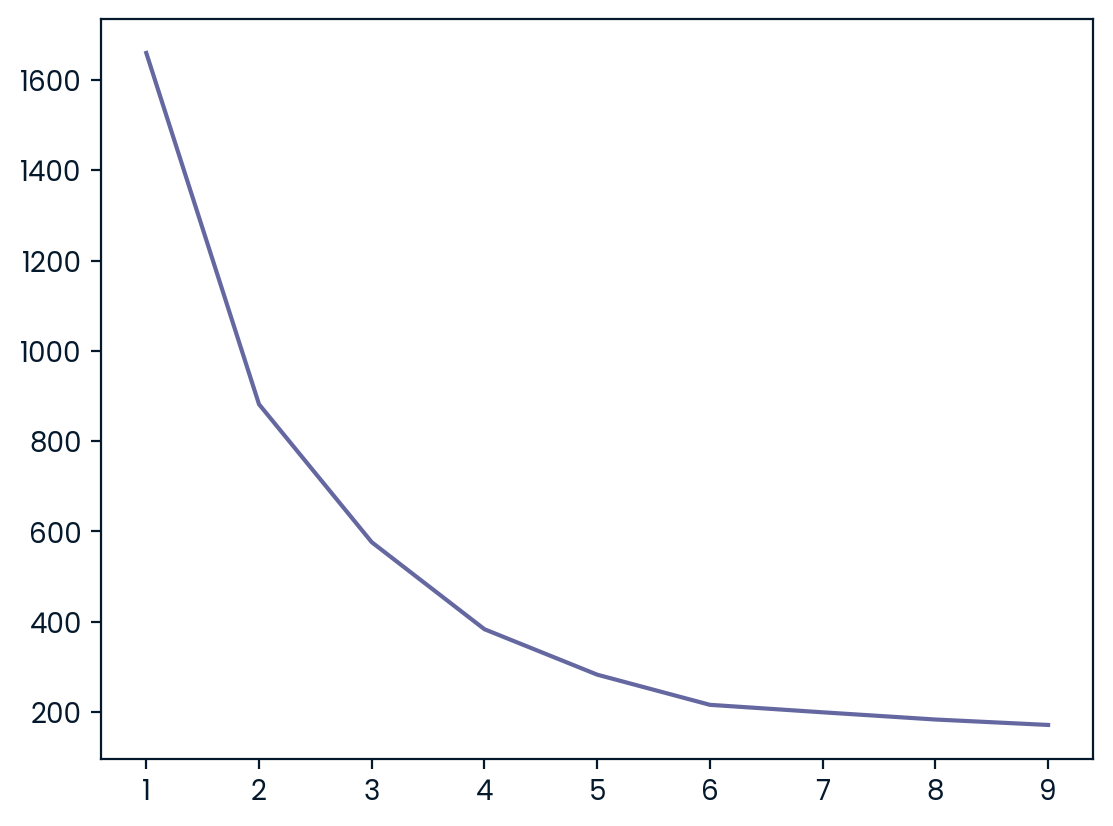

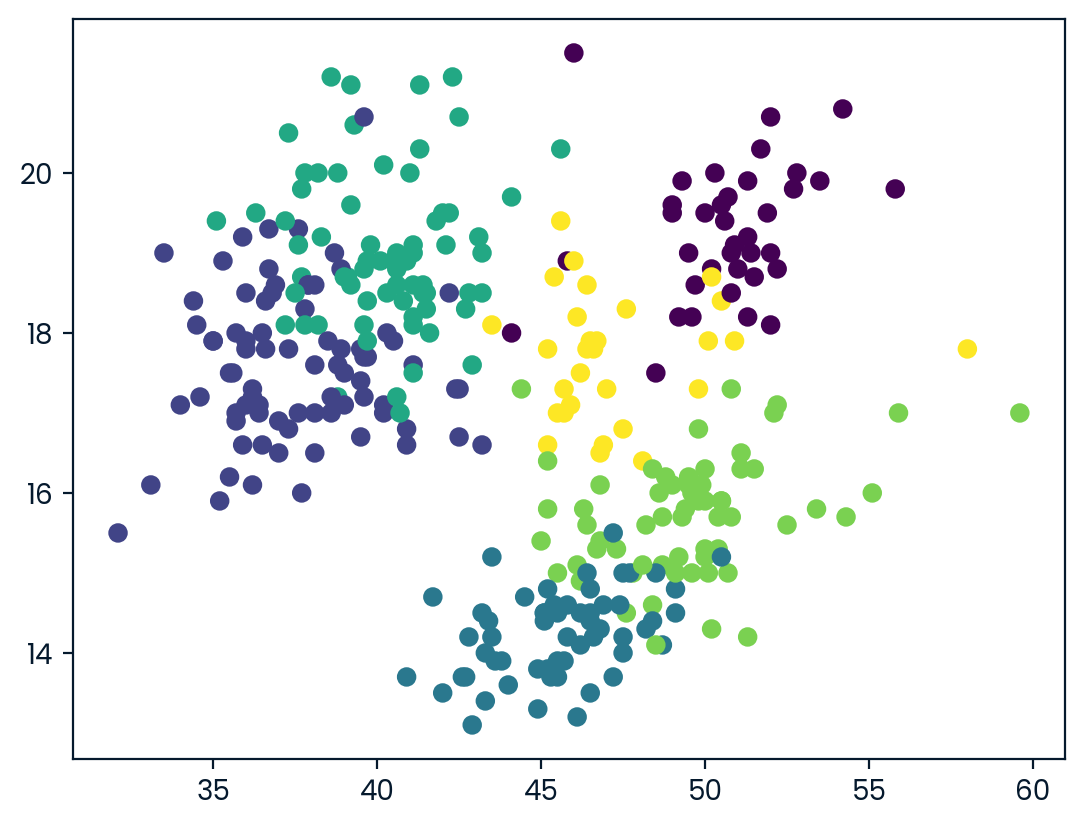

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
label,,,,
0,50.624324,19.270270,199.945946,3953.378378
1,37.580769,17.575641,187.666667,3363.141026
2,45.563793,14.237931,212.706897,4679.741379
3,40.260870,19.026087,191.985507,4035.144928
4,49.473770,15.718033,221.540984,5484.836066
5,47.310345,17.706897,192.758621,3569.827586


In [1]:
# Import Required Packages
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Loading and examining the dataset
penguins_df = pd.read_csv("penguins.csv")
penguins_df.head()

#########################################################################################
# Perform preprocessing steps on the dataset to create dummy variable
# Create dummy variables for the available categorical feature in the dataset, then drop the original column.
# Using get dummies method on the categorical feature
penguins_df['sex_dummies'] = pd.get_dummies(penguins_df['sex'])['MALE']
df = penguins_df.drop(columns=['sex'])

# Recommended: standardizing/scaling before clustering
scaler = StandardScaler()
model = scaler.fit_transform(df)

#########################################################################################
# Determing the optimal number of clusters for k-means clustering
# Perform Elbow analysis to determine the optimal number of clusters for this dataset.
inertia = []

for i in range (1,10):
    kmeans = KMeans(n_clusters=i, random_state=42).fit(model)
    inertia.append(kmeans.inertia_)

plt.plot(range (1,10),inertia)
plt.show()

#########################################################################################
# Run the k-means clustering algorithm
# k-means clustering using sklearn library and visualize the clusters

kmeans = KMeans(n_clusters=6, random_state=42).fit(model)
plt.scatter('culmen_length_mm','culmen_depth_mm',data=df,c=kmeans.labels_)
plt.show()

#'culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm','body_mass_g', 'sex_dummies'

#########################################################################################
# Create a final statistical DataFrame for each cluster
# Create a final characteristic table for each cluster
numeric_columns=penguins_df.columns[0:4]
penguins_df['label']=kmeans.labels_
stat_penguins = penguins_df.groupby('label')[numeric_columns].mean()
stat_penguins

Index(['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm',
       'body_mass_g', 'sex_dummies'],
      dtype='object')


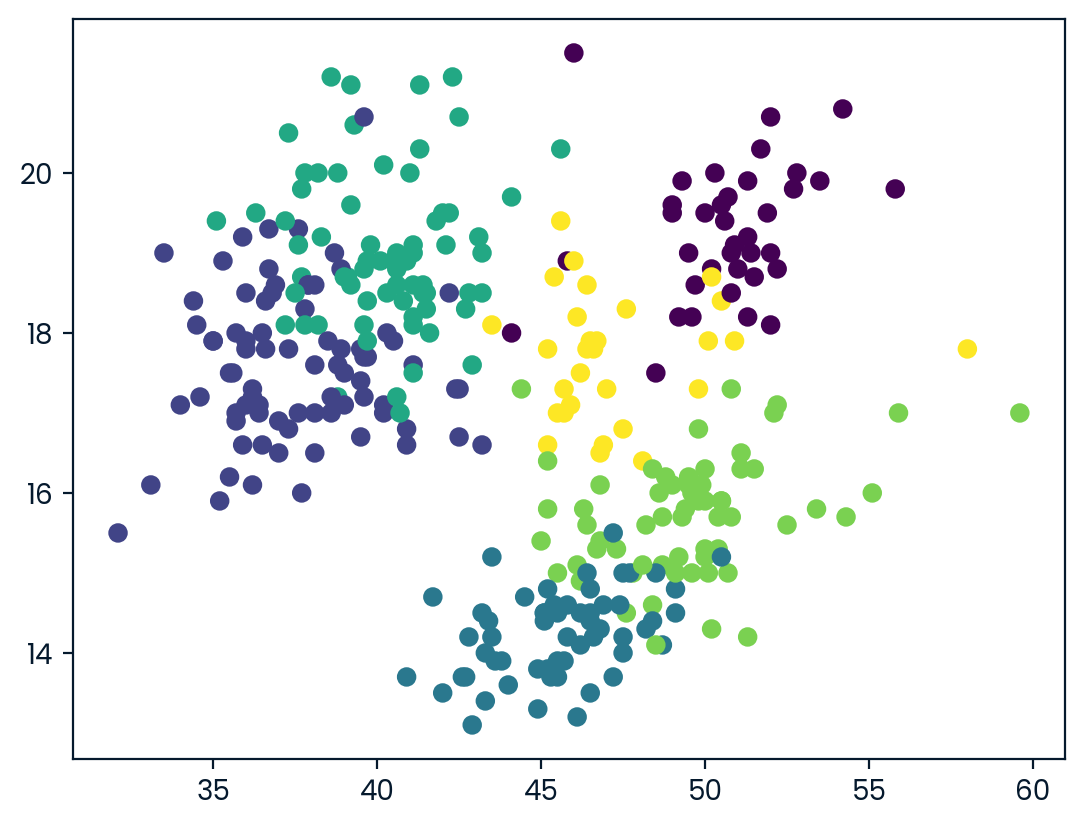

In [15]:
print(df.columns)

plt.scatter('culmen_length_mm','culmen_depth_mm',data=df,c=kmeans.labels_)
plt.show()